In [2]:
!pip install lightgbm

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 462.0 kB/s eta 0:00:02
   --------------- ------------------------ 0.5/1.4 MB 462.0 kB/s eta 0:00:02
   ----------------------- ---------------- 0.8/1.4 MB 586.4 kB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 732.0 kB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 732.0 kB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 732.0 kB/s eta 0:00:01
   -------------------------------------- - 1.3/1.4 MB 592.8 kB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 591.5 kB/s  0:00:02


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from lightgbm import LGBMClassifier, early_stopping

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
sample_submission = pd.read_csv("sample_submission.csv")

print("Train shape:", train.shape)
print("Test shape:", test.shape)
print("Sample submission shape:", sample_submission.shape)

Train shape: (10147, 27)
Test shape: (2537, 26)
Sample submission shape: (2537, 2)


In [5]:
train.head()

,customer_id,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,258868,No Urgent Place,Friend(s),Sunny,80,6PM,Restaurant(<20),1d,Male,21,...,1~3,4~8,4~8,never,1,1,0,0,1,1
1,318369,Work,Alone,Sunny,80,7AM,Restaurant(<20),2h,Male,21,...,1~3,4~8,1~3,less1,1,0,0,1,0,0
2,320906,No Urgent Place,Alone,Sunny,80,10AM,Coffee House,2h,Female,21,...,gt8,4~8,1~3,1~3,1,1,0,0,1,0
3,412393,Work,Alone,Rainy,55,7AM,Restaurant(<20),2h,Female,26,...,less1,4~8,1~3,never,1,1,1,0,1,0
4,290854,Home,Alone,Snowy,30,6PM,Coffee House,1d,Male,31,...,less1,4~8,less1,never,1,1,0,0,1,0


In [6]:
train.tail()

,customer_id,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
10142,201838,Home,Alone,Sunny,80,6PM,Carry out & Take away,2h,Male,below21,...,gt8,gt8,gt8,less1,1,1,0,1,0,0
10143,248838,Home,Partner,Sunny,80,6PM,Coffee House,1d,Male,26,...,NaN,1~3,1~3,less1,1,0,0,1,0,1
10144,173367,No Urgent Place,Alone,Sunny,80,10AM,Restaurant(<20),2h,Female,21,...,never,1~3,never,never,1,0,0,0,1,1
10145,488688,No Urgent Place,Kid(s),Sunny,30,10PM,Restaurant(20-50),2h,Male,46,...,never,1~3,1~3,1~3,1,0,0,0,1,0
10146,431162,Home,Alone,Snowy,30,10PM,Coffee House,2h,Female,36,...,NaN,1~3,1~3,1~3,1,1,0,0,1,0


In [7]:
train.columns.tolist()

['customer_id',
 'destination',
 'passanger',
 'weather',
 'temperature',
 'time',
 'coupon',
 'expiration',
 'gender',
 'age',
 'maritalStatus',
 'has_children',
 'education',
 'occupation',
 'income',
 'car',
 'Bar',
 'CoffeeHouse',
 'CarryAway',
 'RestaurantLessThan20',
 'Restaurant20To50',
 'toCoupon_GEQ5min',
 'toCoupon_GEQ15min',
 'toCoupon_GEQ25min',
 'direction_same',
 'direction_opp',
 'Y']

In [8]:
train["Y"].value_counts()

Y
1    5768
0    4379
Name: count, dtype: int64

In [9]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10147 entries, 0 to 10146
Data columns (total 27 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   customer_id           10147 non-null  int64 
 1   destination           10147 non-null  object
 2   passanger             10147 non-null  object
 3   weather               10147 non-null  object
 4   temperature           10147 non-null  int64 
 5   time                  10147 non-null  object
 6   coupon                10147 non-null  object
 7   expiration            10147 non-null  object
 8   gender                10147 non-null  object
 9   age                   10147 non-null  object
 10  maritalStatus         10147 non-null  object
 11  has_children          10147 non-null  int64 
 12  education             10147 non-null  object
 13  occupation            10147 non-null  object
 14  income                10147 non-null  object
 15  car                   84 non-null   

In [10]:
missing = train.isnull().sum()

missing[missing > 0].sort_values(ascending=False)

car                     10063
CoffeeHouse               172
Restaurant20To50          148
CarryAway                 122
RestaurantLessThan20       97
Bar                        88
dtype: int64

In [11]:
train.duplicated().sum()

np.int64(0)

In [12]:
test.duplicated().sum()

np.int64(0)

In [13]:
print("Unique train IDs:", train["customer_id"].nunique())
print("Unique test IDs:", test["customer_id"].nunique())

overlap = set(train["customer_id"]) & set(test["customer_id"])

print("Train/Test ID overlap:", len(overlap))

Unique train IDs: 10147
Unique test IDs: 2537
Train/Test ID overlap: 0


In [14]:
constant_columns = [
    col for col in train.columns
    if train[col].nunique(dropna=False) <= 1
]

constant_columns

['toCoupon_GEQ5min']

In [15]:
train["toCoupon_GEQ5min"].value_counts(dropna=False)

toCoupon_GEQ5min
1    10147
Name: count, dtype: int64

In [18]:
## we need to find the direction 
pd.crosstab(
    train["direction_same"],
    train["direction_opp"]
)

direction_opp,0,1
direction_same,,
0,0,7994
1,2153,0


In [19]:
(
    train["direction_same"] + train["direction_opp"]
).value_counts()

1    10147
Name: count, dtype: int64

In [20]:
## we found that they are complementary

In [21]:
train.nunique().sort_values()

toCoupon_GEQ5min            1
Y                           2
toCoupon_GEQ15min           2
direction_opp               2
toCoupon_GEQ25min           2
has_children                2
gender                      2
direction_same              2
expiration                  2
destination                 3
temperature                 3
weather                     3
passanger                   4
coupon                      5
Restaurant20To50            5
RestaurantLessThan20        5
CarryAway                   5
Bar                         5
car                         5
time                        5
maritalStatus               5
CoffeeHouse                 5
education                   6
age                         8
income                      9
occupation                 25
customer_id             10147
dtype: int64

In [22]:
train["coupon"].value_counts()

coupon
Coffee House             3191
Restaurant(<20)          2233
Carry out & Take away    1923
Bar                      1623
Restaurant(20-50)        1177
Name: count, dtype: int64

In [24]:
train["destination"].value_counts()

destination
No Urgent Place    5045
Home               2572
Work               2530
Name: count, dtype: int64

In [25]:
train["weather"].value_counts()

weather
Sunny    8015
Snowy    1142
Rainy     990
Name: count, dtype: int64

In [26]:
train["time"].value_counts()

time
6PM     2576
7AM     2530
10AM    1833
2PM     1616
10PM    1592
Name: count, dtype: int64

In [27]:
train["expiration"].value_counts()

expiration
1d    5643
2h    4504
Name: count, dtype: int64

In [28]:
## coupon acceptance by coupon type
coupon_acceptance = (
    train.groupby("coupon")["Y"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

coupon_acceptance

,count,mean
coupon,,
Carry out & Take away,1923,0.735309
Restaurant(<20),2233,0.705329
Coffee House,3191,0.501410
Restaurant(20-50),1177,0.437553
Bar,1623,0.409119


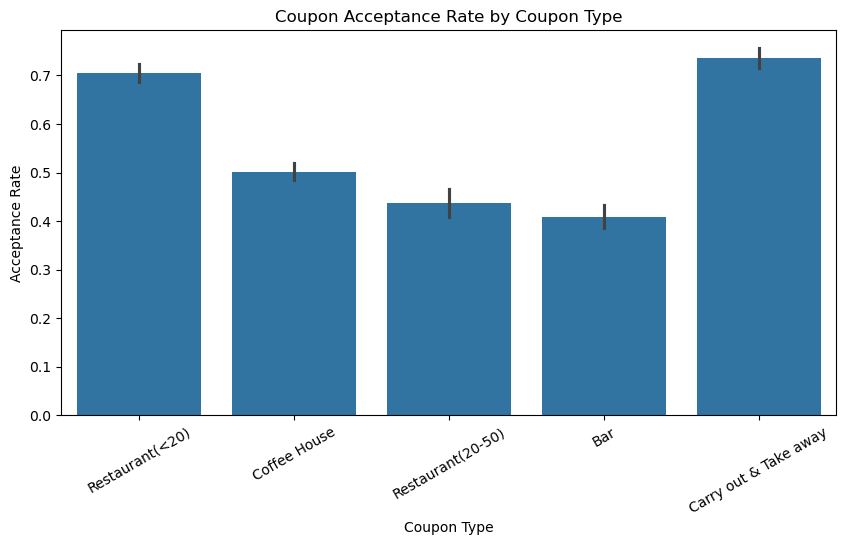

In [30]:
## visualization
plt.figure(figsize=(10, 5))

sns.barplot(
    data=train,
    x="coupon",
    y="Y"
)

plt.xticks(rotation=30)
plt.title("Coupon Acceptance Rate by Coupon Type")
plt.ylabel("Acceptance Rate")
plt.xlabel("Coupon Type")

plt.show()

In [31]:
## acceptance by time
time_acceptance = (
    train.groupby("time")["Y"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

time_acceptance

,count,mean
time,,
2PM,1616,0.655322
10AM,1833,0.615930
6PM,2576,0.582298
10PM,1592,0.508166
7AM,2530,0.502372


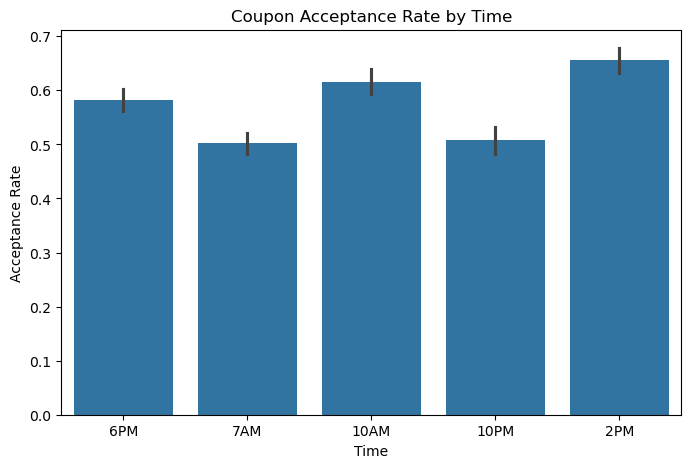

In [32]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x="time",
    y="Y"
)

plt.title("Coupon Acceptance Rate by Time")
plt.ylabel("Acceptance Rate")
plt.xlabel("Time")

plt.show()

In [33]:
## acceptance by weather
weather_acceptance = (
    train.groupby("weather")["Y"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

weather_acceptance

,count,mean
weather,,
Sunny,8015,0.593512
Snowy,1142,0.478109
Rainy,990,0.469697


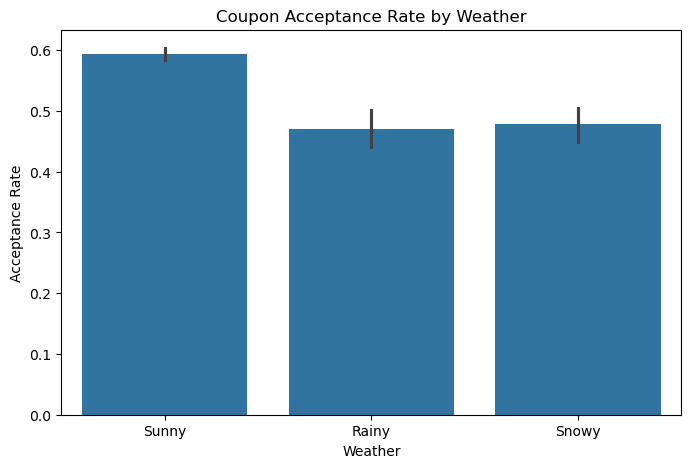

In [34]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x="weather",
    y="Y"
)

plt.title("Coupon Acceptance Rate by Weather")
plt.ylabel("Acceptance Rate")
plt.xlabel("Weather")

plt.show()

In [37]:
## Acceptance by destination
destination_acceptance = (
    train.groupby("destination")["Y"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

destination_acceptance

,count,mean
destination,,
No Urgent Place,5045,0.633895
Home,2572,0.505054
Work,2530,0.502372


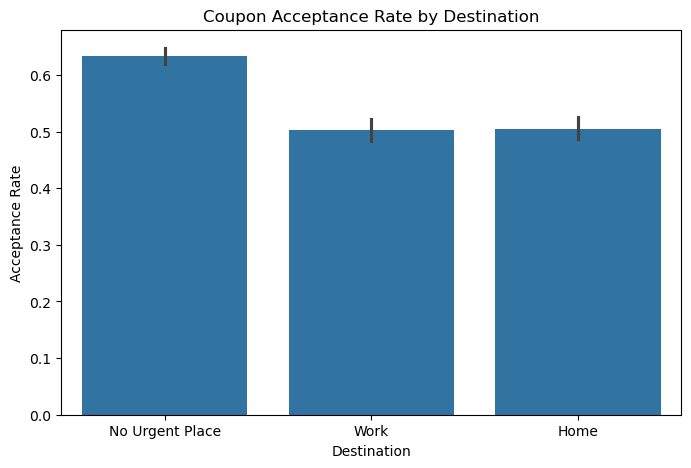

In [38]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=train,
    x="destination",
    y="Y"
)

plt.title("Coupon Acceptance Rate by Destination")
plt.ylabel("Acceptance Rate")
plt.xlabel("Destination")

plt.show()

In [39]:
## Acceptance by expiration
expiration_acceptance = (
    train.groupby("expiration")["Y"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

expiration_acceptance

,count,mean
expiration,,
1d,5643,0.627326
2h,4504,0.494671


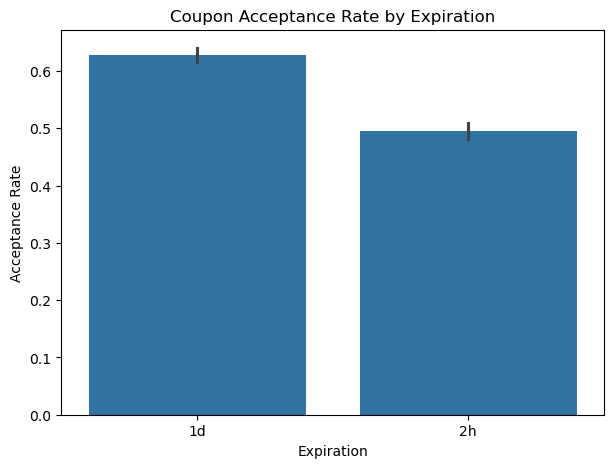

In [40]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=train,
    x="expiration",
    y="Y"
)

plt.title("Coupon Acceptance Rate by Expiration")
plt.ylabel("Acceptance Rate")
plt.xlabel("Expiration")

plt.show()

In [41]:
## Restaurant behaviour
restaurant20_acceptance = (
    train.groupby("Restaurant20To50", dropna=False)["Y"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

restaurant20_acceptance

,count,mean
Restaurant20To50,,
gt8,216,0.666667
4~8,579,0.654577
1~3,2622,0.590008
less1,4889,0.557374
NaN,148,0.554054
never,1693,0.526285


In [42]:
restaurant_less20_acceptance = (
    train.groupby("RestaurantLessThan20", dropna=False)["Y"]
    .agg(["count", "mean"])
    .sort_values("mean", ascending=False)
)

restaurant_less20_acceptance

,count,mean
RestaurantLessThan20,,
NaN,97,0.711340
gt8,1025,0.608780
4~8,2868,0.579847
1~3,4296,0.560521
never,173,0.549133
less1,1688,0.538507


In [44]:
## Separate features and target
X = train.drop(columns=["Y"]).copy()
y = train["Y"].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (10147, 26)
y shape: (10147,)


In [45]:
## remove columns that shouldn't be modeled
drop_columns = [
    "customer_id",
    "toCoupon_GEQ5min",
    "direction_opp"
]

X = X.drop(columns=drop_columns)

print("New X shape:", X.shape)

New X shape: (10147, 23)


In [46]:
## Handle Car
X["car_missing"] = X["car"].isna().astype(int)

In [47]:
X["car_missing"].value_counts()

car_missing
1    10063
0       84
Name: count, dtype: int64

In [48]:
X = X.drop(columns=["car"])

In [49]:
## convert age into a numerical value
train["age"].value_counts(dropna=False)

age
21         2133
26         2033
31         1636
50plus     1431
36         1065
41          879
46          538
below21     432
Name: count, dtype: int64

In [50]:
age_mapping = {
    "below21": 20,
    "21": 21,
    "26": 26,
    "31": 31,
    "36": 36,
    "41": 41,
    "46": 46,
    "50plus": 55
}

X["age_num"] = X["age"].map(age_mapping)

In [51]:
X[["age", "age_num"]].head(10)

,age,age_num
0,21,21
1,21,21
2,21,21
3,26,26
4,31,31
5,50plus,55
6,50plus,55
7,21,21
8,26,26
9,36,36


In [52]:
## Convert income bands
train["income"].value_counts()

income
$25000 - $37499     1622
$12500 - $24999     1464
$37500 - $49999     1444
$100000 or More     1408
$50000 - $62499     1318
Less than $12500     820
$87500 - $99999      712
$75000 - $87499      695
$62500 - $74999      664
Name: count, dtype: int64

In [53]:
income_mapping = {
    "Less than $12500": 6250,
    "$12500 - $24999": 18750,
    "$25000 - $37499": 31250,
    "$37500 - $49999": 43750,
    "$50000 - $62499": 56250,
    "$62500 - $74999": 68750,
    "$75000 - $87499": 81250,
    "$87500 - $99999": 93750,
    "$100000 or More": 110000
}

X["income_mid"] = X["income"].map(income_mapping)

In [54]:
X[["income", "income_mid"]].head(10)

,income,income_mid
0,Less than $12500,6250
1,$37500 - $49999,43750
2,Less than $12500,6250
3,$25000 - $37499,31250
4,$12500 - $24999,18750
5,$25000 - $37499,31250
6,$37500 - $49999,43750
7,$50000 - $62499,56250
8,$50000 - $62499,56250
9,$12500 - $24999,18750


In [55]:
## Income time into hour
train["time"].value_counts()

time
6PM     2576
7AM     2530
10AM    1833
2PM     1616
10PM    1592
Name: count, dtype: int64

In [57]:
time_mapping = {
    "7AM": 7,
    "10AM": 10,
    "2PM": 14,
    "6PM": 18,
    "7PM": 19,
    "10PM": 22
}

X["time_hour"] = X["time"].map(time_mapping)

In [58]:
X[["time", "time_hour"]].head(10)

,time,time_hour
0,6PM,18
1,7AM,7
2,10AM,10
3,7AM,7
4,6PM,18
5,7AM,7
6,6PM,18
7,6PM,18
8,6PM,18
9,10PM,22


In [59]:
## convert customer frequency variables
frequency_columns = [
    "Bar",
    "CoffeeHouse",
    "CarryAway",
    "RestaurantLessThan20",
    "Restaurant20To50"
]

In [60]:
train["CoffeeHouse"].value_counts(dropna=False)

CoffeeHouse
less1    2696
1~3      2586
never    2375
4~8      1423
gt8       895
NaN       172
Name: count, dtype: int64

In [61]:
frequency_mapping = {
    "never": 0,
    "less1": 0.5,
    "1~3": 2,
    "4~8": 6,
    "gt8": 9
}

In [62]:
for col in frequency_columns:
    X[col + "_num"] = X[col].map(frequency_mapping)

In [63]:
X[
    [
        "CoffeeHouse",
        "CoffeeHouse_num",
        "Bar",
        "Bar_num"
    ]
].head(10)

,CoffeeHouse,CoffeeHouse_num,Bar,Bar_num
0,1~3,2.0,less1,0.5
1,1~3,2.0,less1,0.5
2,gt8,9.0,less1,0.5
3,less1,0.5,less1,0.5
4,less1,0.5,1~3,2.0
5,1~3,2.0,1~3,2.0
6,never,0.0,never,0.0
7,1~3,2.0,never,0.0
8,1~3,2.0,never,0.0
9,less1,0.5,less1,0.5


In [64]:
## Check Engineered features
X[
    [
        "age",
        "age_num",
        "income",
        "income_mid",
        "time",
        "time_hour",
        "CoffeeHouse",
        "CoffeeHouse_num",
        "car_missing"
    ]
].head(10)

,age,age_num,income,income_mid,time,time_hour,CoffeeHouse,CoffeeHouse_num,car_missing
0,21,21,Less than $12500,6250,6PM,18,1~3,2.0,1
1,21,21,$37500 - $49999,43750,7AM,7,1~3,2.0,1
2,21,21,Less than $12500,6250,10AM,10,gt8,9.0,1
3,26,26,$25000 - $37499,31250,7AM,7,less1,0.5,1
4,31,31,$12500 - $24999,18750,6PM,18,less1,0.5,1
5,50plus,55,$25000 - $37499,31250,7AM,7,1~3,2.0,1
6,50plus,55,$37500 - $49999,43750,6PM,18,never,0.0,1
7,21,21,$50000 - $62499,56250,6PM,18,1~3,2.0,1
8,26,26,$50000 - $62499,56250,6PM,18,1~3,2.0,1
9,36,36,$12500 - $24999,18750,10PM,22,less1,0.5,1


In [65]:
## Do the same transformations to TEST
def make_features(df):
    df = df.copy()

    # Remove ID / constant / redundant columns
    df = df.drop(
        columns=[
            "customer_id",
            "toCoupon_GEQ5min",
            "direction_opp"
        ],
        errors="ignore"
    )

    # Missingness indicator
    df["car_missing"] = df["car"].isna().astype(int)

    # Drop highly missing raw car feature
    df = df.drop(columns=["car"], errors="ignore")

    # Age
    age_mapping = {
        "below21": 20,
        "21": 21,
        "26": 26,
        "31": 31,
        "36": 36,
        "41": 41,
        "46": 46,
        "50plus": 55
    }

    df["age_num"] = df["age"].map(age_mapping)

    # Income
    income_mapping = {
        "Less than $12500": 6250,
        "$12500 - $24999": 18750,
        "$25000 - $37499": 31250,
        "$37500 - $49999": 43750,
        "$50000 - $62499": 56250,
        "$62500 - $74999": 68750,
        "$75000 - $87499": 81250,
        "$87500 - $99999": 93750,
        "$100000 or More": 110000
    }

    df["income_mid"] = df["income"].map(income_mapping)

    # Time
    time_mapping = {
        "7AM": 7,
        "10AM": 10,
        "2PM": 14,
        "6PM": 18,
        "7PM": 19,
        "10PM": 22
    }

    df["time_hour"] = df["time"].map(time_mapping)

    # Frequency
    frequency_mapping = {
        "never": 0,
        "less1": 0.5,
        "1~3": 2,
        "4~8": 6,
        "gt8": 9
    }

    frequency_columns = [
        "Bar",
        "CoffeeHouse",
        "CarryAway",
        "RestaurantLessThan20",
        "Restaurant20To50"
    ]

    for col in frequency_columns:
        df[col + "_num"] = df[col].map(frequency_mapping)

    return df

In [66]:
## Apply the function
X = make_features(train.drop(columns=["Y"]))
X_test = make_features(test)

print("X shape:", X.shape)
print("X_test shape:", X_test.shape)

X shape: (10147, 31)
X_test shape: (2537, 31)


In [67]:
print("Train feature columns:", len(X.columns))
print("Test feature columns:", len(X_test.columns))

Train feature columns: 31
Test feature columns: 31


In [68]:
print("Columns only in train:")

print(set(X.columns) - set(X_test.columns))

print("\nColumns only in test:")

print(set(X_test.columns) - set(X.columns))

Columns only in train:
set()

Columns only in test:
set()


In [69]:
## Identify categorical columns
categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

categorical_columns

['destination',
 'passanger',
 'weather',
 'time',
 'coupon',
 'expiration',
 'gender',
 'age',
 'maritalStatus',
 'education',
 'occupation',
 'income',
 'Bar',
 'CoffeeHouse',
 'CarryAway',
 'RestaurantLessThan20',
 'Restaurant20To50']

In [70]:
## Convert these to Pandas category type
for col in categorical_columns:
    combined = pd.concat(
        [X[col], X_test[col]],
        axis=0
    ).astype("category")

    categories = combined.cat.categories

    X[col] = pd.Categorical(
        X[col],
        categories=categories
    )

    X_test[col] = pd.Categorical(
        X_test[col],
        categories=categories
    )

In [71]:
X.dtypes

destination                 category
passanger                   category
weather                     category
temperature                    int64
time                        category
coupon                      category
expiration                  category
gender                      category
age                         category
maritalStatus               category
has_children                   int64
education                   category
occupation                  category
income                      category
Bar                         category
CoffeeHouse                 category
CarryAway                   category
RestaurantLessThan20        category
Restaurant20To50            category
toCoupon_GEQ15min              int64
toCoupon_GEQ25min              int64
direction_same                 int64
car_missing                    int64
age_num                        int64
income_mid                     int64
time_hour                      int64
Bar_num                      float64
C

In [72]:
print("Training shape:", X.shape)
print("Test shape:", X_test.shape)

print("\nMissing values in training:")
print(X.isnull().sum().sort_values(ascending=False).head(15))

Training shape: (10147, 31)
Test shape: (2537, 31)

Missing values in training:
CoffeeHouse                 172
CoffeeHouse_num             172
Restaurant20To50            148
Restaurant20To50_num        148
CarryAway_num               122
CarryAway                   122
RestaurantLessThan20         97
RestaurantLessThan20_num     97
Bar_num                      88
Bar                          88
toCoupon_GEQ15min             0
weather                       0
time_hour                     0
income_mid                    0
age_num                       0
dtype: int64


In [73]:
## Create a validation split
X
y

0        1
1        0
2        0
3        0
4        0
        ..
10142    0
10143    1
10144    1
10145    0
10146    0
Name: Y, Length: 10147, dtype: int64

In [74]:
from sklearn.model_selection import train_test_split

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training:", X_train.shape)
print("Validation:", X_valid.shape)

Training: (8117, 31)
Validation: (2030, 31)


In [75]:
##Check target distribution after split
print("Overall acceptance rate:", y.mean())
print("Training acceptance rate:", y_train.mean())
print("Validation acceptance rate:", y_valid.mean())

Overall acceptance rate: 0.5684438750369567
Training acceptance rate: 0.5684366145127511
Validation acceptance rate: 0.5684729064039409


In [76]:
stratify=y

In [77]:
##Create our first LightGBM model
model = LGBMClassifier(
    n_estimators=1500,
    learning_rate=0.025,
    num_leaves=31,
    min_child_samples=25,
    subsample=0.90,
    colsample_bytree=0.90,
    reg_lambda=3.0,
    random_state=42,
    verbosity=-1
)

In [78]:
##Train the model
model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    eval_metric="binary_logloss",
    categorical_feature=categorical_columns,
    callbacks=[
        early_stopping(
            stopping_rounds=100,
            verbose=False
        )
    ]
)

C:\Users\ACER\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  raise LGBMNotFittedError("Estimator not fitted, call fit before exploiting the model.")


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.025
,n_estimators,1500
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,25


In [79]:
##Find the best iteration
print("Best iteration:", model.best_iteration_)

Best iteration: 909


In [80]:
##Make validation predictions
valid_probability = model.predict_proba(X_valid)[:, 1]

valid_probability[:10]

array([0.8510163 , 0.02698933, 0.63747358, 0.33694112, 0.06141855,
       0.81293675, 0.36452878, 0.421812  , 0.07293903, 0.2115104 ])

In [81]:
##Convert probabilities to 0/1
valid_prediction = (
    valid_probability >= 0.50
).astype(int)

valid_prediction[:10]

array([1, 0, 1, 0, 0, 1, 0, 0, 0, 0])

In [82]:
##Calculate accuracy
accuracy = accuracy_score(
    y_valid,
    valid_prediction
)

print("Validation Accuracy:", accuracy)

Validation Accuracy: 0.7753694581280788


In [83]:
##Confusion matrix
cm = confusion_matrix(
    y_valid,
    valid_prediction
)

print(cm)

[[629 247]
 [209 945]]


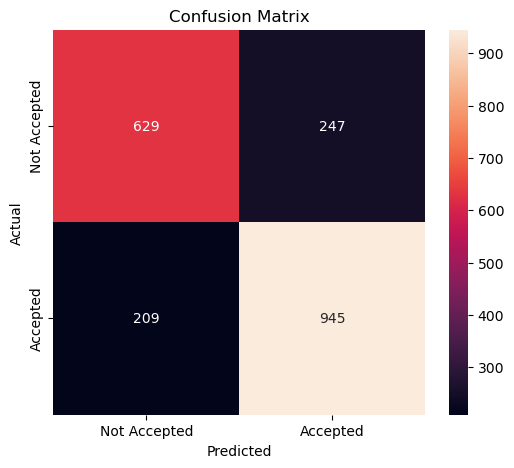

In [84]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Not Accepted", "Accepted"],
    yticklabels=["Not Accepted", "Accepted"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

In [85]:
##Classification report
print(
    classification_report(
        y_valid,
        valid_prediction
    )
)

              precision    recall  f1-score   support

           0       0.75      0.72      0.73       876
           1       0.79      0.82      0.81      1154

    accuracy                           0.78      2030
   macro avg       0.77      0.77      0.77      2030
weighted avg       0.77      0.78      0.77      2030



In [86]:
##Calculate ROC-AUC
auc = roc_auc_score(
    y_valid,
    valid_probability
)

print("Validation ROC-AUC:", auc)

Validation ROC-AUC: 0.8449734099380356


In [87]:
##Feature importance
importance = pd.DataFrame({
    "feature": X_train.columns,
    "importance": model.feature_importances_
})

importance = importance.sort_values(
    "importance",
    ascending=False
)

importance.head(20)

,feature,importance
12,occupation,2815
27,CoffeeHouse_num,2021
13,income,1766
26,Bar_num,1662
24,income_mid,1607
23,age_num,1393
30,Restaurant20To50_num,1254
5,coupon,1247
29,RestaurantLessThan20_num,1195
28,CarryAway_num,1181


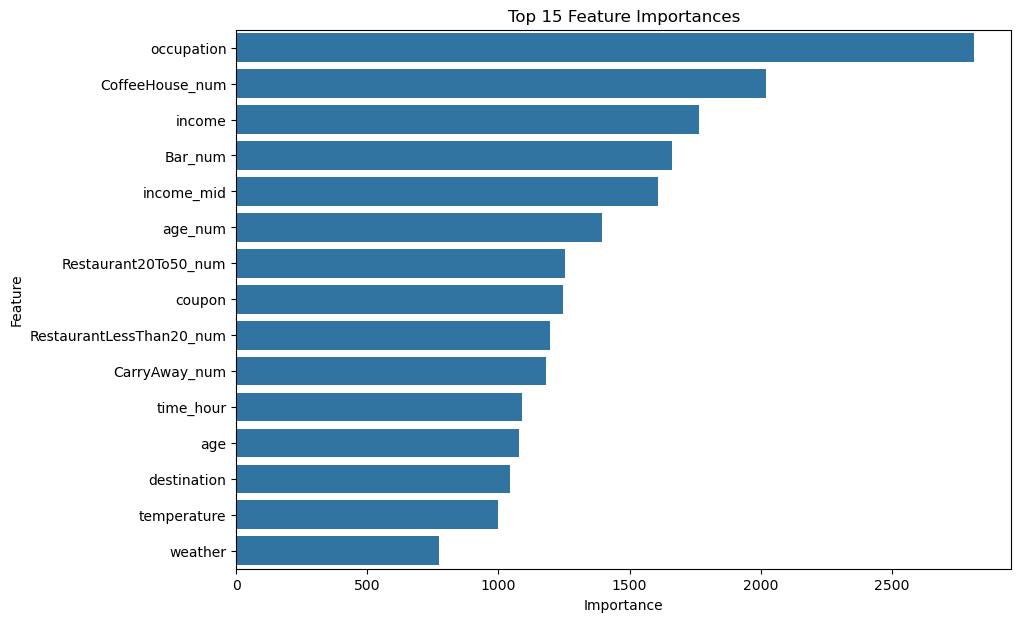

In [88]:
top_features = importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="importance",
    y="feature"
)

plt.title("Top 15 Feature Importances")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

In [89]:
##Compare against the majority baseline
#A trivial model could simply predict:
baseline_prediction = np.ones(
    len(y_valid),
    dtype=int
)

baseline_accuracy = accuracy_score(
    y_valid,
    baseline_prediction
)

print("Baseline Accuracy:", baseline_accuracy)
print("LightGBM Accuracy:", accuracy)

Baseline Accuracy: 0.5684729064039409
LightGBM Accuracy: 0.7753694581280788


In [90]:
##Create the 5 folds
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print(skf)

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)


In [91]:
##Prepare containers for results
oof_predictions = np.zeros(len(X))
test_predictions = np.zeros(len(X_test))

fold_accuracies = []
fold_auc = []
models = []

In [92]:
##Start the cross-validation loop
for fold, (train_idx, valid_idx) in enumerate(
    skf.split(X, y),
    start=1
):
    
    print(f"\n========== Fold {fold} ==========")

    X_train_fold = X.iloc[train_idx]
    y_train_fold = y.iloc[train_idx]

    X_valid_fold = X.iloc[valid_idx]
    y_valid_fold = y.iloc[valid_idx]

    model = LGBMClassifier(
        n_estimators=1500,
        learning_rate=0.025,
        num_leaves=31,
        min_child_samples=25,
        subsample=0.90,
        colsample_bytree=0.90,
        reg_lambda=3.0,
        random_state=42 + fold,
        verbosity=-1
    )

    model.fit(
        X_train_fold,
        y_train_fold,
        eval_set=[(X_valid_fold, y_valid_fold)],
        eval_metric="binary_logloss",
        categorical_feature=categorical_columns,
        callbacks=[
            early_stopping(
                stopping_rounds=100,
                verbose=False
            )
        ]
    )

    # Validation probabilities
    valid_prob = model.predict_proba(
        X_valid_fold
    )[:, 1]

    # Store OOF predictions
    oof_predictions[valid_idx] = valid_prob

    # Validation class predictions
    valid_pred = (
        valid_prob >= 0.50
    ).astype(int)

    # Metrics
    fold_accuracy = accuracy_score(
        y_valid_fold,
        valid_pred
    )

    fold_auc_score = roc_auc_score(
        y_valid_fold,
        valid_prob
    )

    fold_accuracies.append(fold_accuracy)
    fold_auc.append(fold_auc_score)

    # Test predictions
    test_prob = model.predict_proba(
        X_test
    )[:, 1]

    test_predictions += test_prob / skf.n_splits

    models.append(model)

    print("Best iteration:", model.best_iteration_)
    print("Fold Accuracy:", fold_accuracy)
    print("Fold AUC:", fold_auc_score)


========== Fold 1 ==========


C:\Users\ACER\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  raise LGBMNotFittedError("Estimator not fitted, call fit before exploiting the model.")


Best iteration: 1171
Fold Accuracy: 0.7620689655172413
Fold AUC: 0.8349976852401414

========== Fold 2 ==========


C:\Users\ACER\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  raise LGBMNotFittedError("Estimator not fitted, call fit before exploiting the model.")


Best iteration: 1161
Fold Accuracy: 0.767487684729064
Fold AUC: 0.8398235638596742

========== Fold 3 ==========


C:\Users\ACER\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  raise LGBMNotFittedError("Estimator not fitted, call fit before exploiting the model.")


Best iteration: 943
Fold Accuracy: 0.7589945786101527
Fold AUC: 0.8342624411983165

========== Fold 4 ==========


C:\Users\ACER\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  raise LGBMNotFittedError("Estimator not fitted, call fit before exploiting the model.")


Best iteration: 1472
Fold Accuracy: 0.7806801379990143
Fold AUC: 0.8450780572419775

========== Fold 5 ==========


C:\Users\ACER\anaconda3\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  raise LGBMNotFittedError("Estimator not fitted, call fit before exploiting the model.")


Best iteration: 1094
Fold Accuracy: 0.7604731394775751
Fold AUC: 0.8348293314640782


In [94]:
##Look at fold accuracies
fold_accuracies


[0.7620689655172413,
 0.767487684729064,
 0.7589945786101527,
 0.7806801379990143,
 0.7604731394775751]

In [95]:
fold_auc

[0.8349976852401414,
 0.8398235638596742,
 0.8342624411983165,
 0.8450780572419775,
 0.8348293314640782]

In [96]:
##Calculate mean and standard deviation
print(
    "Mean CV Accuracy:",
    np.mean(fold_accuracies)
)

print(
    "CV Accuracy Std:",
    np.std(fold_accuracies)
)

Mean CV Accuracy: 0.7659409012666095
CV Accuracy Std: 0.007909201507232656


In [97]:
##Calculate overall OOF accuracy
oof_class_prediction = (
    oof_predictions >= 0.50
).astype(int)

oof_accuracy = accuracy_score(
    y,
    oof_class_prediction
)

print("OOF Accuracy:", oof_accuracy)

OOF Accuracy: 0.7659406721198384


In [98]:
##Calculate OOF ROC-AUC
oof_auc = roc_auc_score(
    y,
    oof_predictions
)

print("OOF ROC-AUC:", oof_auc)

OOF ROC-AUC: 0.8375556732912948


In [99]:
##Compare all metrics
print("========== FINAL CV SUMMARY ==========")
print("Mean CV Accuracy :", np.mean(fold_accuracies))
print("Accuracy Std     :", np.std(fold_accuracies))
print("OOF Accuracy     :", oof_accuracy)
print("OOF ROC-AUC      :", oof_auc)

========== FINAL CV SUMMARY ==========
Mean CV Accuracy : 0.7659409012666095
Accuracy Std     : 0.007909201507232656
OOF Accuracy     : 0.7659406721198384
OOF ROC-AUC      : 0.8375556732912948


In [100]:
##Check different classification thresholds
threshold_results = []

for threshold in np.arange(
    0.30,
    0.71,
    0.01
):
    
    predictions = (
        oof_predictions >= threshold
    ).astype(int)

    acc = accuracy_score(
        y,
        predictions
    )

    threshold_results.append(
        (threshold, acc)
    )

In [101]:
threshold_df = pd.DataFrame(
    threshold_results,
    columns=["threshold", "accuracy"]
)

threshold_df.sort_values(
    "accuracy",
    ascending=False
).head(10)

,threshold,accuracy
20,0.50,0.765941
21,0.51,0.765645
22,0.52,0.764857
19,0.49,0.764462
18,0.48,0.764364
23,0.53,0.764364
17,0.47,0.763773
24,0.54,0.763477
26,0.56,0.763280
25,0.55,0.763181


In [102]:
##Find the best threshold
best_threshold_row = threshold_df.loc[
    threshold_df["accuracy"].idxmax()
]

best_threshold = best_threshold_row["threshold"]
best_threshold_accuracy = best_threshold_row["accuracy"]

print("Best threshold:", best_threshold)
print("Best OOF accuracy:", best_threshold_accuracy)

Best threshold: 0.5000000000000002
Best OOF accuracy: 0.7659406721198384


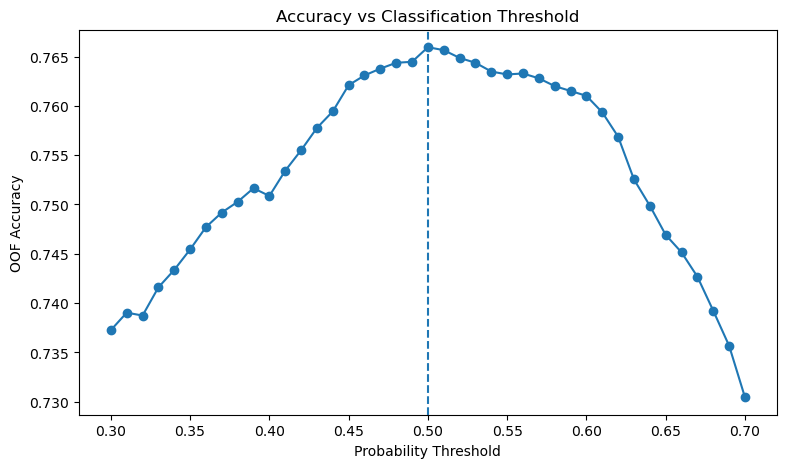

In [103]:
##Plot threshold vs accuracy
plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df["threshold"],
    threshold_df["accuracy"],
    marker="o"
)

plt.axvline(
    best_threshold,
    linestyle="--"
)

plt.xlabel("Probability Threshold")
plt.ylabel("OOF Accuracy")
plt.title("Accuracy vs Classification Threshold")

plt.show()

In [104]:
##OOF confusion matrix
final_oof_prediction = (
    oof_predictions >= best_threshold
).astype(int)

oof_cm = confusion_matrix(
    y,
    final_oof_prediction
)

print(oof_cm)

[[2997 1382]
 [ 993 4775]]


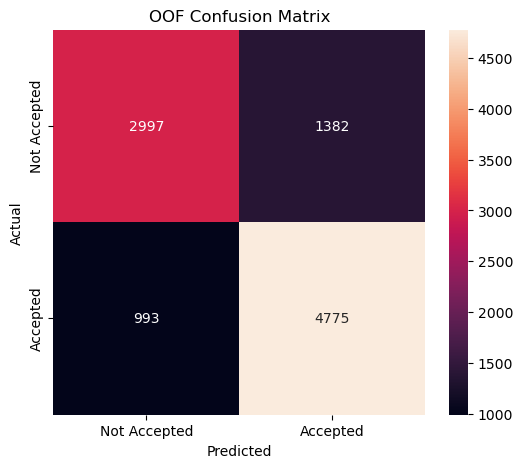

In [105]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    oof_cm,
    annot=True,
    fmt="d",
    xticklabels=["Not Accepted", "Accepted"],
    yticklabels=["Not Accepted", "Accepted"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("OOF Confusion Matrix")

plt.show()

In [106]:
##OOF classification report
print(
    classification_report(
        y,
        final_oof_prediction
    )
)

              precision    recall  f1-score   support

           0       0.75      0.68      0.72      4379
           1       0.78      0.83      0.80      5768

    accuracy                           0.77     10147
   macro avg       0.76      0.76      0.76     10147
weighted avg       0.77      0.77      0.76     10147



In [107]:
##Inspect test probabilities
print("Number of test predictions:", len(test_predictions))
print("Minimum probability:", test_predictions.min())
print("Maximum probability:", test_predictions.max())
print("Mean probability:", test_predictions.mean())

Number of test predictions: 2537
Minimum probability: 0.011187332023763298
Maximum probability: 0.9961808533147316
Mean probability: 0.5663165025099945


In [108]:
assert np.all(
    (test_predictions >= 0) &
    (test_predictions <= 1)
)

print("All test probabilities are valid.")

All test probabilities are valid.


In [109]:
##Use the selected threshold
best_threshold

np.float64(0.5000000000000002)

In [110]:
print("Selected threshold:", best_threshold)

Selected threshold: 0.5000000000000002


In [111]:
final_test_prediction = (
    test_predictions >= best_threshold
).astype(int)

In [112]:
print("Number of predictions:", len(final_test_prediction))
print("Unique prediction values:", np.unique(final_test_prediction))

Number of predictions: 2537
Unique prediction values: [0 1]


In [113]:
##Look at the prediction distribution
pd.Series(final_test_prediction).value_counts()

1    1516
0    1021
Name: count, dtype: int64

In [114]:
pd.Series(final_test_prediction).value_counts(normalize=True)

1    0.597556
0    0.402444
Name: proportion, dtype: float64

In [115]:
##Create the submission DataFrameCreate the submission DataFrame
submission = pd.DataFrame({
    "customer_id": test["customer_id"],
    "Y": final_test_prediction
})

In [116]:
submission.head(10)

,customer_id,Y
0,374679,1
1,469678,1
2,216140,0
3,184301,0
4,148720,1
5,145576,1
6,194322,1
7,198210,0
8,305477,1
9,257384,1


In [117]:
##Check submission shape
print("Submission shape:", submission.shape)

Submission shape: (2537, 2)


In [118]:
##Check column names
print(submission.columns.tolist())

['customer_id', 'Y']


In [119]:
##Validate customer IDs
print(
    "IDs match test:",
    submission["customer_id"].equals(
        test["customer_id"]
    )
)

IDs match test: True


In [120]:
print(
    "Unique submission IDs:",
    submission["customer_id"].nunique()
)

Unique submission IDs: 2537


In [121]:
###Validate predictions
print(
    "Missing Y values:",
    submission["Y"].isna().sum()
)

print(
    "Unique Y values:",
    submission["Y"].unique()
)

Missing Y values: 0
Unique Y values: [1 0]


In [122]:
##Final submission preview
submission.head(20)

,customer_id,Y
0,374679,1
1,469678,1
2,216140,0
3,184301,0
4,148720,1
5,145576,1
6,194322,1
7,198210,0
8,305477,1
9,257384,1


In [123]:
submission.tail(20)

,customer_id,Y
2517,496600,1
2518,484720,0
2519,490128,0
2520,384600,1
2521,428592,1
2522,387776,0
2523,472824,0
2524,417933,1
2525,305047,1
2526,243420,0


In [124]:
##Save the submission
submission.to_csv(
    "submission.csv",
    index=False
)

print("submission.csv created successfully!")

submission.csv created successfully!


In [125]:
check_submission = pd.read_csv(
    "submission.csv"
)

print(check_submission.shape)
print(check_submission.head())
print(check_submission.columns.tolist())

(2537, 2)
   customer_id  Y
0       374679  1
1       469678  1
2       216140  0
3       184301  0
4       148720  1
['customer_id', 'Y']


In [126]:
##Final automated QA
assert submission.shape == (len(test), 2)

assert list(submission.columns) == [
    "customer_id",
    "Y"
]

assert submission["customer_id"].equals(
    test["customer_id"]
)

assert submission["customer_id"].nunique() == len(test)

assert submission["Y"].notna().all()

assert set(
    submission["Y"].unique()
).issubset({0, 1})

print("================================")
print("SUBMISSION QA PASSED")
print("================================")

print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())
print("Unique IDs:", submission["customer_id"].nunique())
print("Prediction values:", sorted(submission["Y"].unique()))

SUBMISSION QA PASSED
Rows: 2537
Columns: ['customer_id', 'Y']
Unique IDs: 2537
Prediction values: [np.int64(0), np.int64(1)]


In [ ]:
###Final project summary
                         COUPON ACCEPTANCE PROJECT

CSV DATA
   │
   ▼
Data Understanding
   │
   ├── Shape
   ├── Columns
   ├── Target distribution
   └── Missing values
   │
   ▼
Data Quality
   │
   ├── Duplicate check
   ├── Train/Test ID overlap
   ├── Constant columns
   └── Redundant columns
   │
   ▼
EDA
   │
   ├── Coupon
   ├── Time
   ├── Weather
   ├── Destination
   ├── Expiration
   └── Customer behavior
   │
   ▼
Feature Engineering
   │
   ├── Age → age_num
   ├── Income → income_mid
   ├── Time → time_hour
   ├── Frequency → numerical features
   └── Car missingness → car_missing
   │
   ▼
LightGBM
   │
   ▼
5-Fold Stratified CV
   │
   ├── Fold 1
   ├── Fold 2
   ├── Fold 3
   ├── Fold 4
   └── Fold 5
   │
   ▼
OOF Predictions
   │
   ├── Accuracy
   ├── ROC-AUC
   ├── Confusion Matrix
   └── Threshold analysis
   │
   ▼
Average Test Predictions
   │
   ▼
0 / 1 Prediction
   │
   ▼
submission.csv